# Cuaderno 1. Entrenamiento y persistencia de los pipelines (Saber 11)

**Curso:** Machine Learning | **Integrante:** Jaime Alejandro Ocampo Quiceno

**Qué hace este cuaderno:** toma el modelo predictivo de las TIA anteriores (puntaje global de Saber 11) y lo organiza en **dos pipelines**:

1. `pipeline_prep`: arregla los datos (rellena nulos y convierte las categorías en columnas 0/1).
2. `pipeline_modelo`: escala los datos y entrena la red neuronal.

Después se guardan los dos con `joblib` para usarlos en el Cuaderno 2 sin volver a entrenar.

**Etapa CRISP-DM:** preparación de datos, modelamiento, evaluación y despliegue (MLOps nivel 0).

In [1]:
# Todas las librerías se importan aquí, al inicio
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn, scipy, joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Semilla fija para que los resultados se puedan repetir
SEMILLA = 42
sns.set_theme(style="whitegrid")

# Rutas relativas desde la carpeta notebooks/
RAIZ = Path("..")
RUTA_DATOS = RAIZ / "data" / "saber11_eda.csv"
RUTA_ARTEFACTOS = RAIZ / "artifacts"
RUTA_RESULTADOS = RAIZ / "resultados"
RUTA_ARTEFACTOS.mkdir(exist_ok=True)
RUTA_RESULTADOS.mkdir(exist_ok=True)

# Comprobación del entorno: la ruta debe quedar dentro de venv_ml
print("Python ejecutable:", sys.executable)
print("Python:", sys.version.split()[0])
print("numpy:", np.__version__, "| pandas:", pd.__version__)
print("scipy:", scipy.__version__, "| scikit-learn:", sklearn.__version__, "| joblib:", joblib.__version__)

Python ejecutable: c:\Users\aleh\Desktop\laboratorio_uv_ml\venv_ml\Scripts\python.exe
Python: 3.12.16
numpy: 2.5.5 | pandas: 3.1.1
scipy: 1.18.1 | scikit-learn: 1.9.1 | joblib: 1.6.0


**Análisis.** Esta celda confirma con qué Python y con qué versiones se entrena. Si la ruta de `sys.executable` no está dentro de `venv_ml`, el cuaderno está usando otro entorno y hay que cambiar el kernel. Guardar las versiones sirve porque el Cuaderno 2 debe cargar los archivos con versiones iguales, o el modelo puede fallar o dar resultados distintos.

## 1. Carga de datos y variables

Se usan las mismas variables de la TIA 3: el INSE (numérica) y cuatro variables categóricas. La salida es `PUNT_GLOBAL`. Los puntajes por materia no se usan porque no se conocen antes de la prueba (regla de negocio 1.3.2).

In [2]:
# Carga y limpieza mínima: solo se quitan las pruebas anuladas (puntaje 0).
# Los nulos NO se rellenan aquí; se rellenan dentro del pipeline para que las medianas
# y modas se aprendan solo con los datos de entrenamiento (evita fuga de información)
df = pd.read_csv(RUTA_DATOS)
print("Filas y columnas originales:", df.shape)
df = df[df["PUNT_GLOBAL"] > 0].copy()
print("Filas sin pruebas anuladas:", len(df))

# Misma muestra de 6.000 estudiantes de las TIA anteriores
df = df.sample(6000, random_state=SEMILLA).reset_index(drop=True)

VARS_NUMERICAS = ["ESTU_INSE_INDIVIDUAL"]
VARS_CATEGORICAS = ["FAMI_TIENEINTERNET", "FAMI_TIENECOMPUTADOR", "COLE_NATURALEZA", "COLE_AREA_UBICACION"]
VARIABLE_SALIDA = "PUNT_GLOBAL"

X = df[VARS_NUMERICAS + VARS_CATEGORICAS]
y = df[VARIABLE_SALIDA]
print("Nulos por variable de entrada:")
print(X.isna().sum())

Filas y columnas originales: (504872, 22)
Filas sin pruebas anuladas: 504792
Nulos por variable de entrada:
ESTU_INSE_INDIVIDUAL    178
FAMI_TIENEINTERNET      169
FAMI_TIENECOMPUTADOR    253
COLE_NATURALEZA           0
COLE_AREA_UBICACION       0
dtype: int64


**Variables de entrada:** `ESTU_INSE_INDIVIDUAL` (índice, numérica), `FAMI_TIENEINTERNET`, `FAMI_TIENECOMPUTADOR`, `COLE_NATURALEZA` y `COLE_AREA_UBICACION` (categóricas).
**Variable de salida:** `PUNT_GLOBAL` (puntos, de 0 a 500).

**Análisis.** Las cinco entradas tienen pocos nulos (alrededor de 3 %), por eso se pueden rellenar con mediana y moda sin cambiar mucho los datos. Se dejan sin rellenar en esta etapa para hacerlo después de separar entrenamiento y prueba.

## 2. División en entrenamiento y prueba

Primero se separa y después se ajusta todo. Así la prueba queda sin tocar.

In [3]:
X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.25, random_state=SEMILLA)
print("Entrenamiento:", X_ent.shape, "| Prueba:", X_pru.shape)

Entrenamiento: (4500, 5) | Prueba: (1500, 5)


## 3. Pipeline de preprocesamiento (`pipeline_prep`)

- Numérica: se rellena con la **mediana**.
- Categóricas: se rellenan con la **moda** y se pasan a columnas 0/1 (one hot).

Se ajusta (`fit`) solo con `X_ent`. Con la prueba se usa solo `transform`.

In [4]:
preprocesador = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), VARS_NUMERICAS),
        ("cat", Pipeline([
            ("imputador", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), VARS_CATEGORICAS),
    ],
    verbose_feature_names_out=False,
)
# set_output("pandas") hace que la salida conserve los nombres de las columnas
pipeline_prep = Pipeline([("preprocesador", preprocesador)]).set_output(transform="pandas")

# fit solo con entrenamiento; transform para entrenamiento y prueba
X_ent_prep = pipeline_prep.fit_transform(X_ent)
X_pru_prep = pipeline_prep.transform(X_pru)

print("Columnas después del preprocesamiento:", list(X_ent_prep.columns))
print("Nulos en entrenamiento preprocesado:", int(X_ent_prep.isna().sum().sum()))
print("Mediana aprendida del INSE:", pipeline_prep.named_steps["preprocesador"].named_transformers_["num"].statistics_)
X_ent_prep.head()

Columnas después del preprocesamiento: ['ESTU_INSE_INDIVIDUAL', 'FAMI_TIENEINTERNET_No', 'FAMI_TIENEINTERNET_Si', 'FAMI_TIENECOMPUTADOR_No', 'FAMI_TIENECOMPUTADOR_Si', 'COLE_NATURALEZA_NO OFICIAL', 'COLE_NATURALEZA_OFICIAL', 'COLE_AREA_UBICACION_RURAL', 'COLE_AREA_UBICACION_URBANO']
Nulos en entrenamiento preprocesado: 0
Mediana aprendida del INSE: [50.51216504]


,ESTU_INSE_INDIVIDUAL,FAMI_TIENEINTERNET_No,FAMI_TIENEINTERNET_Si,FAMI_TIENECOMPUTADOR_No,FAMI_TIENECOMPUTADOR_Si,COLE_NATURALEZA_NO OFICIAL,COLE_NATURALEZA_OFICIAL,COLE_AREA_UBICACION_RURAL,COLE_AREA_UBICACION_URBANO
2847,52.872617,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0
4336,70.995955,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0
3386,41.832622,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0
1721,52.984394,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
2404,38.771391,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0


**Análisis.** Después del pipeline no quedan nulos y las cuatro variables de sí/no quedan como 8 columnas 0/1, más el INSE: 9 entradas en total, las mismas de la TIA 3. La mediana del INSE que aprendió el pipeline viene solo del entrenamiento; ese valor se guarda dentro del archivo `.joblib` y se usa igual en producción.

## 4. Pipeline de modelamiento (`pipeline_modelo`)

Se usa la red neuronal ganadora de la búsqueda en rejilla de la TIA 3: **una capa oculta de 32 neuronas, activación relu y alpha = 0,01**. Antes de la red se estandarizan las entradas, y la salida también se estandariza para que la red aprenda mejor (`TransformedTargetRegressor`).

No se incluyó PCA: solo hay 9 entradas, casi todas 0/1, y reducir dimensiones aquí quitaría interpretación sin ganar nada.

In [5]:
pipeline_modelo = TransformedTargetRegressor(
    regressor=Pipeline([
        ("escalador", StandardScaler()),
        ("mlp", MLPRegressor(hidden_layer_sizes=(32,), activation="relu", alpha=0.01,
                             solver="adam", max_iter=2000, random_state=SEMILLA)),
    ]),
    transformer=StandardScaler(),
)

# fit solo con los datos de entrenamiento ya preprocesados
pipeline_modelo.fit(X_ent_prep, y_ent)
print("Modelo entrenado. Iteraciones usadas:", pipeline_modelo.regressor_.named_steps["mlp"].n_iter_)

Modelo entrenado. Iteraciones usadas: 54


## 5. Evaluación en el conjunto de prueba

RMSE = 43.878 | MAE = 35.336 | R2 = 0.204
RMSE de la línea base (predecir siempre la media): 49.222


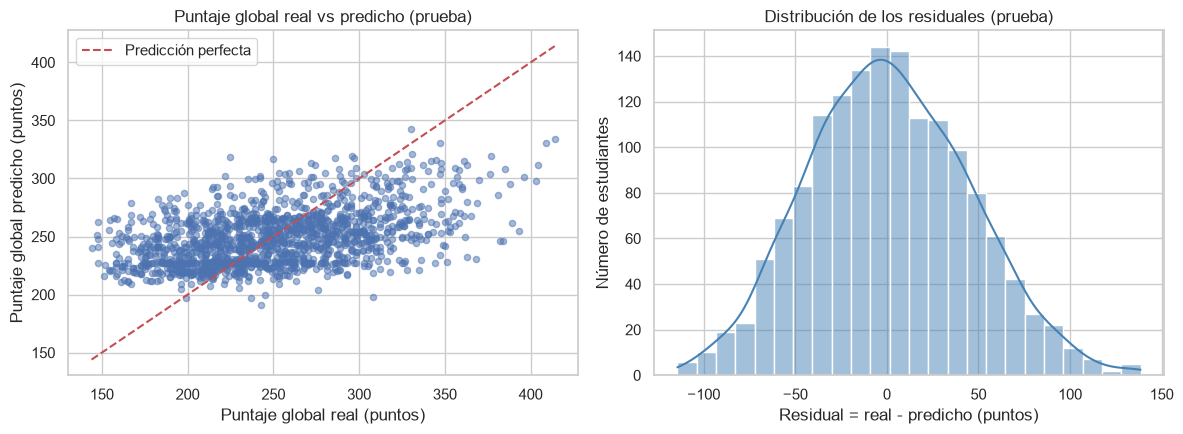

In [6]:
# Predicción sobre prueba usando solo transform y predict
y_pred = pipeline_modelo.predict(X_pru_prep)

rmse = float(np.sqrt(mean_squared_error(y_pru, y_pred)))
mae = float(mean_absolute_error(y_pru, y_pred))
r2 = float(r2_score(y_pru, y_pred))
rmse_base = float(np.sqrt(mean_squared_error(y_pru, np.full(len(y_pru), y_ent.mean()))))
print(f"RMSE = {rmse:.3f} | MAE = {mae:.3f} | R2 = {r2:.3f}")
print(f"RMSE de la línea base (predecir siempre la media): {rmse_base:.3f}")

# Gráficas de validación: real vs predicho y distribución de residuales
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
ejes[0].scatter(y_pru, y_pred, alpha=0.5, s=20)
lim = [min(y_pru.min(), y_pred.min()), max(y_pru.max(), y_pred.max())]
ejes[0].plot(lim, lim, "r--", label="Predicción perfecta")
ejes[0].set_title("Puntaje global real vs predicho (prueba)")
ejes[0].set_xlabel("Puntaje global real (puntos)")
ejes[0].set_ylabel("Puntaje global predicho (puntos)")
ejes[0].legend()
sns.histplot(y_pru - y_pred, kde=True, ax=ejes[1], color="steelblue")
ejes[1].set_title("Distribución de los residuales (prueba)")
ejes[1].set_xlabel("Residual = real - predicho (puntos)")
ejes[1].set_ylabel("Número de estudiantes")
plt.tight_layout()
plt.show()

**Análisis.** Qué se observa: el modelo supera a la línea base (predecir siempre la media), pero explica solo una parte pequeña del puntaje (R² cerca de 0,2) y se equivoca en promedio unos 35 puntos. Las predicciones se concentran en el centro y los residuales tienen forma de campana centrada en cero. Por qué ocurre: con solo cinco variables del hogar y del colegio no se conoce el esfuerzo del estudiante ni la calidad del colegio. Qué implica: el modelo sirve para ordenar estudiantes de menor a mayor puntaje esperado (que es lo que necesita el programa), no para dar el puntaje exacto.

In [7]:
# Criterio de negocio (1.5): de los estudiantes con puntaje real < 211, qué porcentaje queda en el 25 % priorizado
CUPO = 0.25
n_cupos = int(np.floor(len(y_pru) * CUPO))
orden = np.argsort(y_pred, kind="mergesort")
priorizado = np.zeros(len(y_pru), dtype=bool)
priorizado[orden[:n_cupos]] = True
bajo_real = (y_pru.values < 211)
captura = float((priorizado & bajo_real).sum() / bajo_real.sum())
print(f"Tasa de captura: {captura:.1%} (meta: 50 %; al azar: cerca de 25 %)")

Tasa de captura: 43.9% (meta: 50 %; al azar: cerca de 25 %)


**Análisis.** La tasa de captura es la medida de negocio: de los estudiantes que de verdad sacaron menos de 211, cuántos quedaron dentro del cupo. Mejora mucho frente al azar (25 %), pero queda por debajo de la meta del 50 %, igual que en la TIA 4. Es una evaluación retrospectiva: no mide cuánto subiría el puntaje con el refuerzo.

## 6. Guardar los pipelines con joblib

Se guardan los dos objetos ya ajustados. También se guardan las métricas y las predicciones de prueba para compararlas en el Cuaderno 2.

In [8]:
ruta_prep = RUTA_ARTEFACTOS / "pipeline_prep.joblib"
ruta_modelo = RUTA_ARTEFACTOS / "pipeline_modelo.joblib"
joblib.dump(pipeline_prep, ruta_prep)
joblib.dump(pipeline_modelo, ruta_modelo)

# Métricas y predicciones de referencia para comprobar en el Cuaderno 2
metricas = {"rmse": rmse, "mae": mae, "r2": r2, "rmse_base": rmse_base, "captura": captura,
            "versiones": {"python": sys.version.split()[0], "numpy": np.__version__,
                          "scipy": scipy.__version__, "sklearn": sklearn.__version__, "joblib": joblib.__version__}}
with open(RUTA_RESULTADOS / "metricas_cuaderno1.json", "w") as f:
    json.dump(metricas, f, indent=2)
np.save(RUTA_RESULTADOS / "pred_prueba_cuaderno1.npy", y_pred)

for r in (ruta_prep, ruta_modelo):
    print(r.name, "->", round(r.stat().st_size / 1024, 1), "KB")

pipeline_prep.joblib -> 4.5 KB
pipeline_modelo.joblib -> 21.5 KB


## 7. Prueba con assert: cargar y comparar en este mismo cuaderno

Se cargan los archivos en variables nuevas y se comprueba que las predicciones son idénticas. Si algo falla, el `assert` lanza un error.

In [9]:
prep_cargado = joblib.load(ruta_prep)
modelo_cargado = joblib.load(ruta_modelo)

# Solo transform y predict: no se vuelve a entrenar nada
y_pred_cargado = modelo_cargado.predict(prep_cargado.transform(X_pru))

assert np.allclose(y_pred, y_pred_cargado), "Las predicciones no coinciden"
print("OK: las predicciones del modelo guardado y cargado son idénticas.")
print("Diferencia máxima:", float(np.abs(y_pred - y_pred_cargado).max()))

OK: las predicciones del modelo guardado y cargado son idénticas.
Diferencia máxima: 0.0


**Análisis.** El `assert` pasó: los pipelines guardados conservan todo lo aprendido (medianas, modas, categorías del one hot, escalas y pesos de la red). Por eso en producción solo hace falta cargar los archivos y llamar a `transform` y `predict`.